In [1]:
import pandas as pd

data=pd.read_csv("cleaned_dataset.csv")

# Select numerical columns
numerical_cols = data.select_dtypes(include='number')

# Calculate descriptive statistics
statistics = numerical_cols.describe()

statistics

,Math_Score,Reading_Score,Writing_Score
count,1001.000000,1001.000000,1001.000000
mean,66.115884,69.166833,68.073926
std,15.090081,14.472841,15.023133
min,0.000000,17.000000,10.000000
25%,57.000000,60.000000,58.000000
50%,66.000000,70.000000,69.000000
75%,77.000000,79.000000,78.000000
max,100.000000,100.000000,100.000000


In [2]:
# descriptive stats for numeric values
descriptive_stats = pd.DataFrame()

descriptive_stats['Mean'] = numerical_cols.mean()
descriptive_stats['Median'] = numerical_cols.median()
descriptive_stats['Mode'] = numerical_cols.mode().iloc[0]
descriptive_stats['Minimum'] = numerical_cols.min()
descriptive_stats['Maximum'] = numerical_cols.max()

descriptive_stats['Range'] = (
    numerical_cols.max() - numerical_cols.min()
)

descriptive_stats['Standard Deviation'] = numerical_cols.std()
descriptive_stats['Variance'] = numerical_cols.var()

descriptive_stats

,Mean,Median,Mode,Minimum,Maximum,Range,Standard Deviation,Variance
Math_Score,66.115884,66.0,66,0,100,100,15.090081,227.710557
Reading_Score,69.166833,70.0,70,17,100,83,14.472841,209.463139
Writing_Score,68.073926,69.0,69,10,100,90,15.023133,225.694529


In [3]:
# descriptive stats for categoric values
categorical_cols = data.select_dtypes(include='object')

for col in categorical_cols:
    print(col, ":", data[col].mode()[0])

Gender : female
Race_Ethnicity : group c
Parental_Education : some college
Lunch_Type : standard
Test_Preparation : none


C:\Users\SKY TECH\AppData\Local\Temp\ipykernel_206324\1287794464.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = data.select_dtypes(include='object')


In [4]:
# Analysis of Categorical Variables
for col in categorical_cols:
    print("\nFrequency of", col)
    print(data[col].value_counts())


Frequency of Gender
Gender
female    521
male      480
Name: count, dtype: int64

Frequency of Race_Ethnicity
Race_Ethnicity
group c    328
group d    257
group b    191
group e    137
group a     88
Name: count, dtype: int64

Frequency of Parental_Education
Parental_Education
some college          236
associate's degree    218
high school           197
some high school      175
bachelor's degree     119
master's degree        56
Name: count, dtype: int64

Frequency of Lunch_Type
Lunch_Type
standard        651
free/reduced    350
Name: count, dtype: int64

Frequency of Test_Preparation
Test_Preparation
none         647
completed    354
Name: count, dtype: int64


In [5]:
# calculate % 
for col in categorical_cols:
    print("\nPercentage distribution of", col)
    print(data[col].value_counts(normalize=True) * 100)


Percentage distribution of Gender
Gender
female    52.047952
male      47.952048
Name: proportion, dtype: float64

Percentage distribution of Race_Ethnicity
Race_Ethnicity
group c    32.767233
group d    25.674326
group b    19.080919
group e    13.686314
group a     8.791209
Name: proportion, dtype: float64

Percentage distribution of Parental_Education
Parental_Education
some college          23.576424
associate's degree    21.778222
high school           19.680320
some high school      17.482517
bachelor's degree     11.888112
master's degree        5.594406
Name: proportion, dtype: float64

Percentage distribution of Lunch_Type
Lunch_Type
standard        65.034965
free/reduced    34.965035
Name: proportion, dtype: float64

Percentage distribution of Test_Preparation
Test_Preparation
none         64.635365
completed    35.364635
Name: proportion, dtype: float64


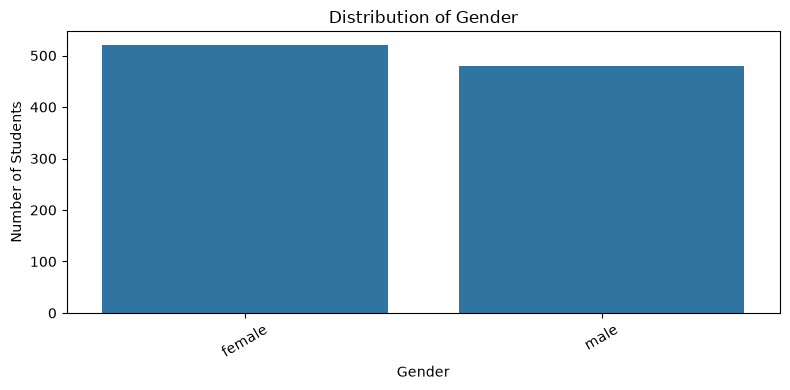

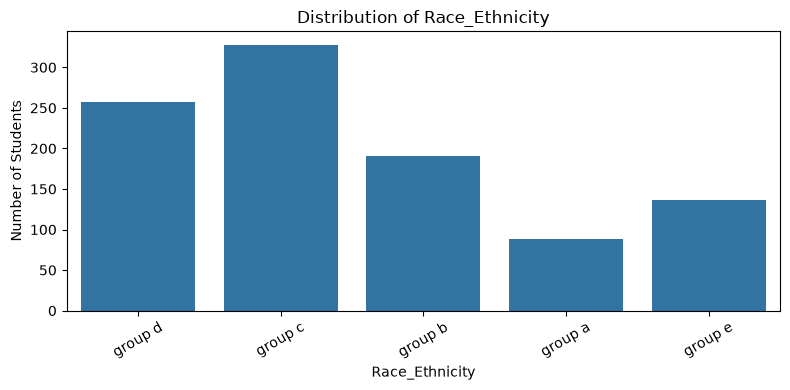

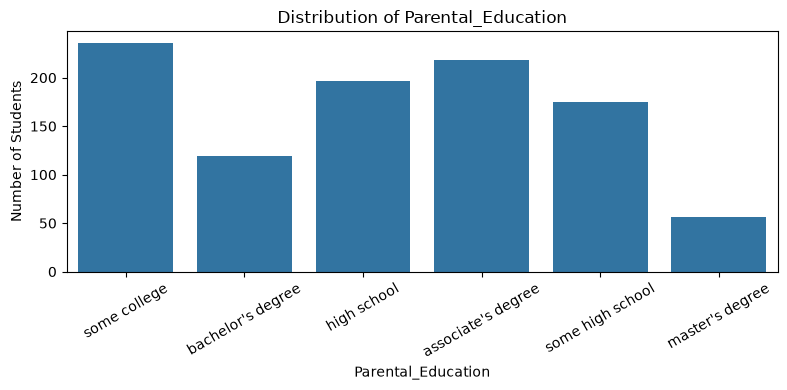

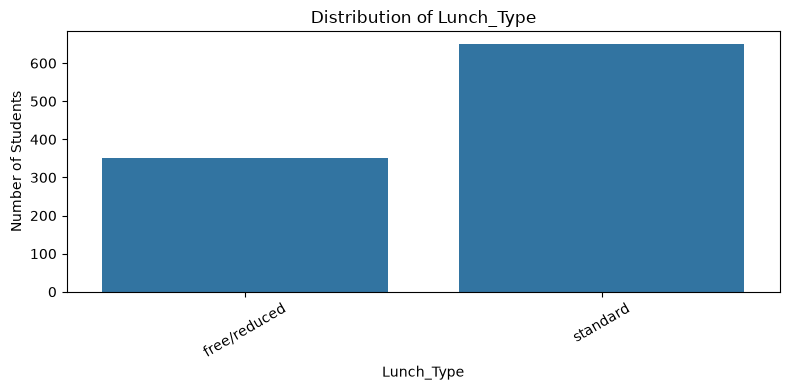

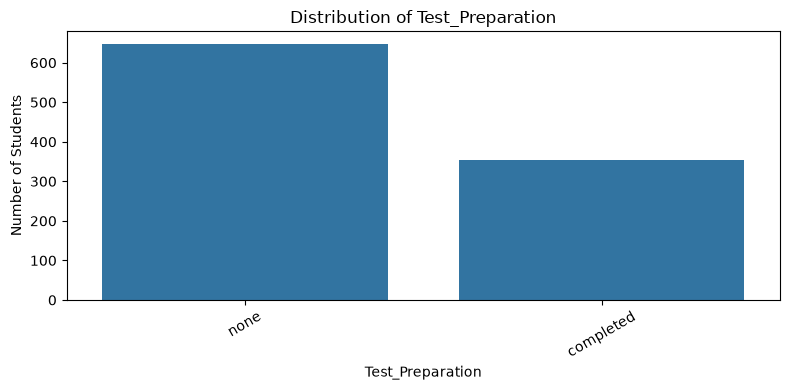

In [6]:
#Visualizing categorical variables by Bar chart
import matplotlib.pyplot as plt
import seaborn as sns

for col in categorical_cols:

    plt.figure(figsize=(8, 4))

    sns.countplot(data=data, x=col)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Number of Students')

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [7]:
# outlier detection

score_cols = [
    'Math_Score',
    'Reading_Score',
    'Writing_Score'
]

for col in score_cols:

    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = data[
        (data[col] < lower_limit) |
        (data[col] > upper_limit)
    ]

    print("\nSubject:", col)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))


Subject: Math_Score
Lower Limit: 27.0
Upper Limit: 107.0
Number of Outliers: 8

Subject: Reading_Score
Lower Limit: 31.5
Upper Limit: 107.5
Number of Outliers: 9

Subject: Writing_Score
Lower Limit: 28.0
Upper Limit: 108.0
Number of Outliers: 7


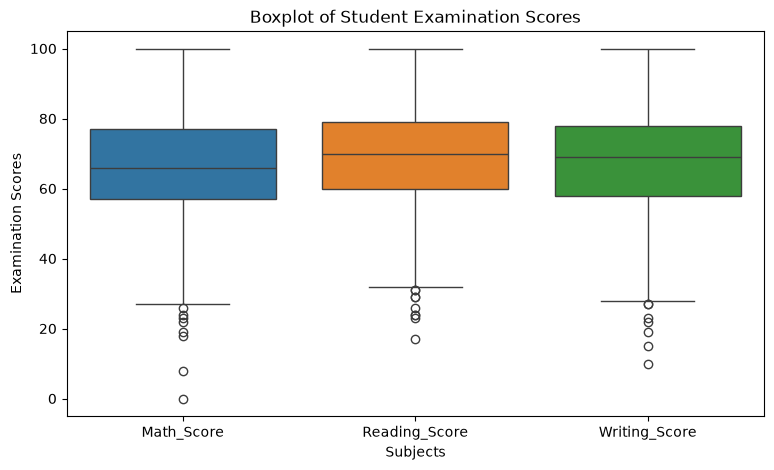

In [8]:
#Visualize outliers using boxplots

plt.figure(figsize=(9, 5))

sns.boxplot(data=data[score_cols])

plt.title('Boxplot of Student Examination Scores')
plt.xlabel('Subjects')
plt.ylabel('Examination Scores')

plt.show()

In [9]:
# Correlation matrix

correlation_matrix = data[score_cols].corr()

correlation_matrix

,Math_Score,Reading_Score,Writing_Score
Math_Score,1.000000,0.804101,0.776697
Reading_Score,0.804101,1.000000,0.925944
Writing_Score,0.776697,0.925944,1.000000


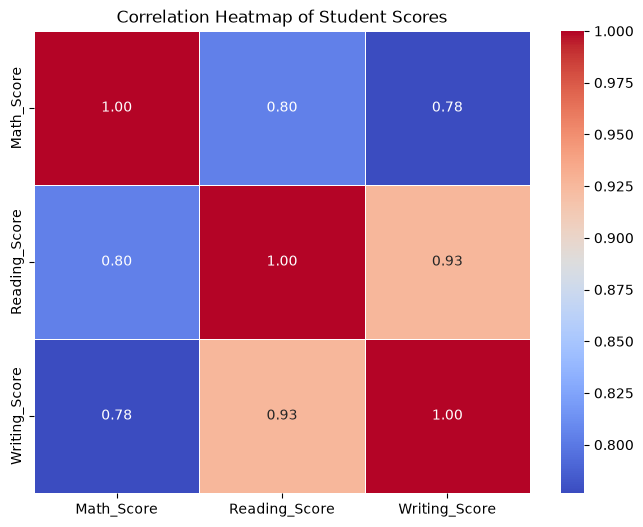

In [10]:
# Correlation heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Student Scores')

plt.show()

In [11]:
# Relationship Between Categorical Variables and Student Performance

categorical_cols = [
    'Gender',
    'Race_Ethnicity',
    'Parental_Education',
    'Lunch_Type',
    'Test_Preparation'
]

for col in categorical_cols:

    print(f"\nAverage Scores by {col}")

    print(
        data.groupby(col)[score_cols]
        .mean()
        .round(2)
    )


Average Scores by Gender
        Math_Score  Reading_Score  Writing_Score
Gender                                          
female       63.49          72.33          72.08
male         68.97          65.74          63.72

Average Scores by Race_Ethnicity
                Math_Score  Reading_Score  Writing_Score
Race_Ethnicity                                          
group a              61.75          64.74          63.20
group b              63.52          67.11          65.72
group c              64.68          69.39          67.76
group d              67.26          70.10          70.22
group e              73.81          72.58          71.21

Average Scores by Parental_Education
                    Math_Score  Reading_Score  Writing_Score
Parental_Education                                          
associate's degree       67.68          70.58          69.39
bachelor's degree        69.18          72.85          73.06
high school              62.34          64.90          62.78
ma

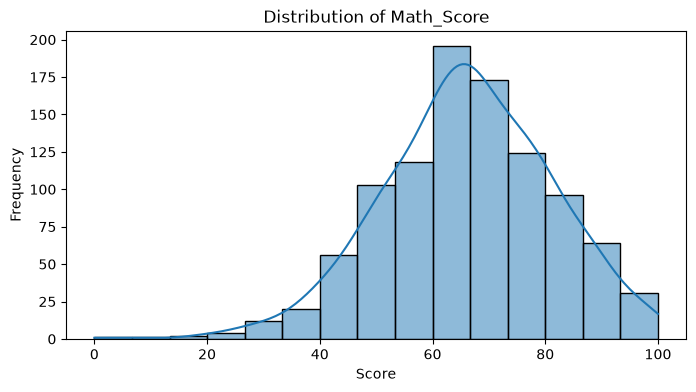

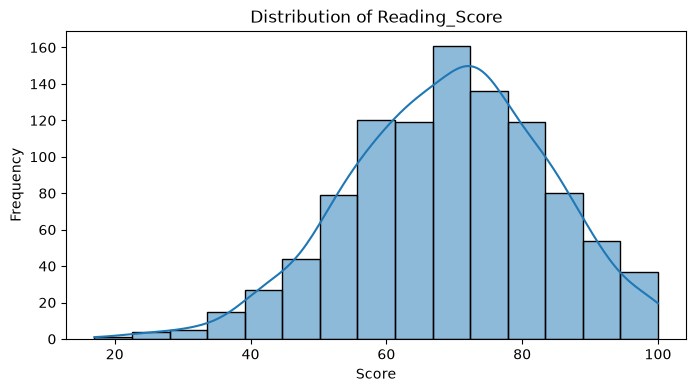

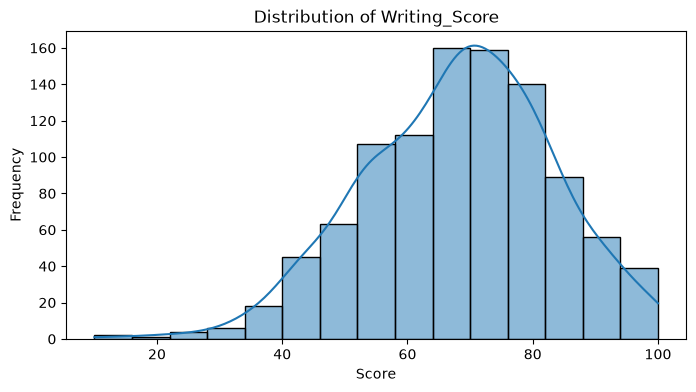

In [12]:
# Histogram for exam score

for col in score_cols:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=data,
        x=col,
        bins=15,
        kde=True
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel('Score')
    plt.ylabel('Frequency')

    plt.show()